# Step 01: Data Preparation
**Project:** Dynamic Agent Staffing Optimization (Google) · DADS 5250 Module 7 Hackathon

**Goal:** clean the workbook once and save files the rest of the team can use.

**Outputs** (in the `data/clean/` folder):
| File | What it holds |
|---|---|
| `countries.csv` | One row per country: salary, eligibility threshold, existing agents (Jan 2026) |
| `eligible_signups.csv` | One row per eligible advertiser sign-up |
| `monthly_eligible_demand.csv` | Per country and month: eligible sign-ups and their average budget |

In [1]:
import os
import pandas as pd
import matplotlib.pyplot as plt

DATA_FILE = "../data/raw/DADS5250_Hackathon_Google_Data.xlsx"
OUT_DIR = "../data/clean"

# 2025 is not a leap year, so 2025-02-29 is invalid. Those rows are moved to Feb 28 to keep them in February.
FEB29_FIX = "2025-02-28"

## 1. Read the workbook

In [2]:
sheets = pd.read_excel(DATA_FILE, sheet_name=None)
for name, sheet in sheets.items():
    print(f"{name:30s} {sheet.shape}")

README                         (9, 2)
Agent Salary and Threshold     (22, 3)
Advertiser Sign-ups            (499644, 4)
Existing Agent Staffing        (22, 2)


In [3]:
pd.set_option("display.max_colwidth", None)
sheets["README"]

,DADS 5250: Generative AI in Practice,Unnamed: 1
0,Module 7 Hackathon,"Dynamic Agent Staffing Optimization, contributed by Google."
1,NaN,NaN
2,Sheet,What it holds
3,Agent Salary and Threshold,"Annual agent salary and the advertiser eligibility threshold, per country, in USD. 22 countries."
4,Advertiser Sign-ups,"One row per sign-up for 2024 and 2025: Advertiser ID, Country, Date of sign-up, Projected annual advertising budget."
5,Existing Agent Staffing,Agent headcount per country as of January 2026. 22 countries.
6,NaN,NaN
7,Note,"The problem statement lists the salary file and the eligibility threshold file separately. They are the same spreadsheet, so both live on one sheet here."
8,Source,Combined from the four files linked in the Google problem statement. Values are unchanged.


In [4]:
countries = sheets["Agent Salary and Threshold"]
staffing = sheets["Existing Agent Staffing"]
signups = sheets["Advertiser Sign-ups"].copy()
signups.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget
0,A000001,USA,2024-01-01 00:00:00,84376
1,A000002,USA,2024-01-01 00:00:00,57297
2,A000003,USA,2024-01-01 00:00:00,34081
3,A000004,USA,2024-01-01 00:00:00,154506
4,A000005,USA,2024-01-01 00:00:00,23604


## 2. Basic checks

In [5]:
# Every country should appear in all three sheets
c1, c2, c3 = set(countries["Country"]), set(staffing["Country"]), set(signups["Country"])
print("Countries:", len(c1), "| same in all sheets:", c1 == c2 == c3)

# Empty cells and duplicate IDs
print("Empty cells:", int(signups.isna().sum().sum() + countries.isna().sum().sum() + staffing.isna().sum().sum()))
print("Duplicate advertiser IDs:", signups["Advertiser_ID"].duplicated().sum())

# Budget range
print("Budget range:", signups["Projected_Annual_Budget"].min(), "to", signups["Projected_Annual_Budget"].max())

Countries: 22 | same in all sheets: True
Empty cells: 0
Duplicate advertiser IDs: 0
Budget range: 500 to 250000


## 3. Fix the invalid date (2025-02-29)

In [6]:
bad = signups["Sign_Up_Date"].astype(str).str.startswith("2025-02-29")
print("Rows with 2025-02-29:", bad.sum())
print(signups.loc[bad, "Country"].value_counts().to_string())

signups.loc[bad, "Sign_Up_Date"] = FEB29_FIX
print(f"Moved to {FEB29_FIX}")

Rows with 2025-02-29: 920
Country
USA             108
China            82
Brazil           80
India            72
France           66
Canada           59
Germany          57
Japan            55
UK               45
Mexico           40
Australia        39
South Korea      33
Italy            32
Spain            23
South Africa     22
Turkey           22
Vietnam          21
Poland           18
Indonesia        17
Argentina        13
Thailand         10
UAE               6
Moved to 2025-02-28


## 4. Convert dates

In [7]:
signups["Sign_Up_Date"] = pd.to_datetime(signups["Sign_Up_Date"])
signups["Year"] = signups["Sign_Up_Date"].dt.year
signups["Month"] = signups["Sign_Up_Date"].dt.month

print("Date range:", signups["Sign_Up_Date"].min().date(), "to", signups["Sign_Up_Date"].max().date())
print(signups["Year"].value_counts().sort_index().to_string())

Date range: 2024-01-01 to 2025-12-31
Year
2024    252019
2025    247625


## 5. Join the country table

In [8]:
df = signups.merge(countries, on="Country", how="left", validate="many_to_one")
assert df["Advertiser_Eligibility_Threshold_USD"].notna().all()
df.head()

,Advertiser_ID,Country,Sign_Up_Date,Projected_Annual_Budget,Year,Month,Annual_Agent_Salary_USD,Advertiser_Eligibility_Threshold_USD
0,A000001,USA,2024-01-01,84376,2024,1,77721,35000
1,A000002,USA,2024-01-01,57297,2024,1,77721,35000
2,A000003,USA,2024-01-01,34081,2024,1,77721,35000
3,A000004,USA,2024-01-01,154506,2024,1,77721,35000
4,A000005,USA,2024-01-01,23604,2024,1,77721,35000


## 6. Keep eligible advertisers
An advertiser is eligible when its projected budget is **above** its own country's threshold.

In [9]:
df["Eligible"] = df["Projected_Annual_Budget"] > df["Advertiser_Eligibility_Threshold_USD"]
print(f"Eligible: {df['Eligible'].sum():,} of {len(df):,} ({df['Eligible'].mean():.1%})")

rate = (df.groupby("Country")["Eligible"].agg(Signups="size", Eligible="sum", Rate="mean")
          .sort_values("Eligible", ascending=False))
rate.style.format({"Rate": "{:.1%}"})

Eligible: 212,334 of 499,644 (42.5%)


,Signups,Eligible,Rate
Country,,,
India,42330,28886,68.2%
USA,60112,26116,43.4%
Japan,29865,13359,44.7%
UK,36247,12445,34.3%
China,39137,11599,29.6%
Brazil,36290,11444,31.5%
Germany,33183,10744,32.4%
Italy,21053,10249,48.7%
Mexico,18140,9897,54.6%


## 7. Summarize per country and month

In [10]:
eligible = df[df["Eligible"]]

monthly = (eligible.groupby(["Country", "Year", "Month"])
                   .agg(Eligible_Signups=("Advertiser_ID", "count"),
                        Avg_Budget=("Projected_Annual_Budget", "mean"))
                   .reset_index())
monthly["Avg_Budget"] = monthly["Avg_Budget"].round(2)

print("Rows:", len(monthly), "(expected 22 countries x 24 months = 528)")
monthly.head()

Rows: 528 (expected 22 countries x 24 months = 528)


,Country,Year,Month,Eligible_Signups,Avg_Budget
0,Argentina,2024,1,53,12313.58
1,Argentina,2024,2,66,10162.45
2,Argentina,2024,3,69,11351.57
3,Argentina,2024,4,71,11207.24
4,Argentina,2024,5,67,12859.40


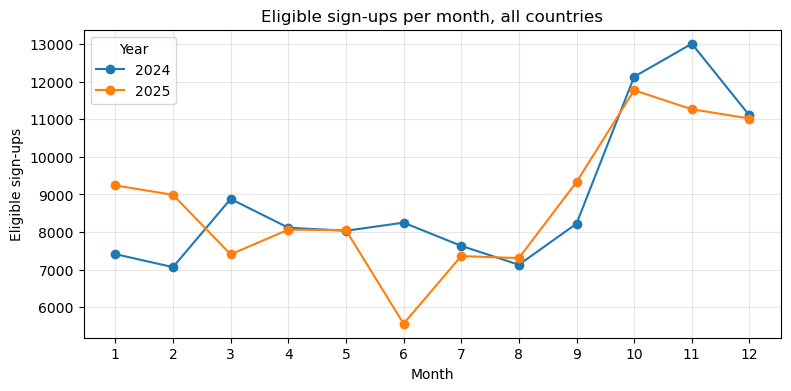

In [11]:
total = monthly.groupby(["Year", "Month"])["Eligible_Signups"].sum().unstack(0)
total.plot(marker="o", figsize=(9, 4), title="Eligible sign-ups per month, all countries")
plt.xlabel("Month")
plt.ylabel("Eligible sign-ups")
plt.xticks(range(1, 13))
plt.grid(alpha=0.3)
plt.show()

## 8. Save the clean files

In [12]:
os.makedirs(OUT_DIR, exist_ok=True)

country_table = countries.merge(staffing, on="Country", how="left", validate="one_to_one")
country_table.to_csv(f"{OUT_DIR}/countries.csv", index=False)

cols = ["Advertiser_ID", "Country", "Sign_Up_Date", "Year", "Month", "Projected_Annual_Budget"]
eligible[cols].to_csv(f"{OUT_DIR}/eligible_signups.csv", index=False)

monthly.to_csv(f"{OUT_DIR}/monthly_eligible_demand.csv", index=False)

for f in sorted(os.listdir(OUT_DIR)):
    print(f)

countries.csv
eligible_signups.csv
forecast_2026.csv
monthly_eligible_demand.csv


## Decisions (for the report)
- **2025-02-29:** 920 rows had this invalid date. They were moved to `FEB29_FIX` (set in the first code cell).
- **Eligibility:** budget must be strictly greater than the country's threshold.
- **Budget:** used as given; the FAQ says Google already projected it and it stays fixed during the year.